<a href="https://colab.research.google.com/github/WendelLeander/PhishEvade/blob/main/feature_scaling_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Scaling and Array Generation
### Obfuscation-Aware Feature Engineering for Phishing URL Detection

This notebook converts the raw 13-feature dataset produced in the feature extraction pipeline into the **final scaled feature matrix** that the classifiers will train on.

**Why scaling is needed.** The 13 features live on wildly different numeric scales: `url_length` can run into the hundreds or thousands of characters, while the ratio features are bounded between 0 and 1. If left unscaled, models that rely on distance calculations or gradient-based optimisation (Logistic Regression in particular) would let large-magnitude features dominate the decision boundary regardless of how predictive they really are. Tree ensembles (Random Forest, XGBoost, AdaBoost) are insensitive to scale, but scaling is still applied **consistently across every feature configuration** (traditional, obfuscation-aware and combined), so that any performance difference reflects genuine feature informativeness rather than inconsistent preprocessing.

**Pipeline**

| Step | Procedure | Result |
|---|---|---|
| 1 | Isolate the features into scaling groups: `min_max_cols` (lengths and ratios) and `z_score_cols` (counts, variance and entropy); binary flags are left as they are | Three non-overlapping lists covering all 13 features |
| 2 | Fit **`MinMaxScaler`** on `min_max_cols` | Values mapped linearly to the 0.0 to 1.0 range |
| 3 | Fit **`StandardScaler`** on `z_score_cols` | Mean 0, unit variance |
| 4 | Pass the two binary flags through untouched | Values stay 0 / 1 |
| 5 | **Array generation**: assemble a strictly numerical, fixed-order feature matrix | NumPy array of shape (rows, 13) |
| 6 | Export the scaled matrix as a new CSV | `Final Dataset_Scaled.csv` |

**Tools:** pandas and NumPy for the data frame and array, scikit-learn (`MinMaxScaler`, `StandardScaler`) for scaling, matplotlib for the before/after plots.


## Install Dependencies (run once)

`%pip` installs into the **same Python environment the notebook kernel is using**, which avoids the common `ModuleNotFoundError` caused by installing with a different `pip` than the one Jupyter runs on. If an import error persists after installing, restart the kernel (*Kernel > Restart*) and run the notebook again.


In [10]:
# Run once. Safe to re-run; already-installed packages are skipped.
%pip install -q pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Setup and Input Data

The input is `Final Dataset_Features.csv` (the output of Milestones 3 and 4): one row per URL with the `url` string, the binary `label` (`0` = benign, `1` = malicious) and the 13 raw engineered features. The feature order below is fixed and is the column order of the final matrix.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

# DATA_PATH = "../Dataset/Extracted_Features.csv"  # Local path
DATA_PATH = 'https://raw.githubusercontent.com/WendelLeander/PhishEvade/refs/heads/main/Dataset/Extracted_Features.csv'
OUTPUT_PATH = "../Dataset/Final_Dataset.csv"
RANDOM_SEED = 42

FEATURE_ORDER = [
    "url_length", "domain_length", "path_length",                                   # Level 1
    "subdomain_count", "path_depth", "query_params_count",                          # Level 2: structural
    "digit_ratio", "special_char_ratio", "token_variance", "domain_entropy",        # Level 2: ratios / variance / entropy
    "redirect_key_flag", "nested_url_flag", "query_encoding_ratio",                 # Level 2: query analysis
]
LEVEL1 = FEATURE_ORDER[:3]

In [12]:
raw = pd.read_csv(DATA_PATH)

missing = [c for c in ["label"] + FEATURE_ORDER if c not in raw.columns]
assert not missing, f"missing columns in {DATA_PATH}: {missing}"

features_raw = raw[FEATURE_ORDER].copy()          # untouched raw features (kept for before/after comparison)
labels = raw["label"].astype(int)

print(f"Loaded {len(raw):,} rows from '{DATA_PATH}'")
print("Class balance:", labels.value_counts().sort_index().to_dict(), "(0 = benign, 1 = malicious)")
print("Missing values in features:", int(features_raw.isna().sum().sum()))
raw.head()

Loaded 10,000 rows from 'https://raw.githubusercontent.com/WendelLeander/PhishEvade/refs/heads/main/Dataset/Extracted_Features.csv'
Class balance: {0: 5000, 1: 5000} (0 = benign, 1 = malicious)
Missing values in features: 0


,url,label,url_length,domain_length,path_length,subdomain_count,path_depth,query_params_count,digit_ratio,special_char_ratio,token_variance,domain_entropy,redirect_key_flag,nested_url_flag,query_encoding_ratio
0,51-75-63-68.cprapid.com/eu/track.php?16d6oev751pp7e2ffowz,1,57,23,13,1,2,1,0.280702,0.157895,31.288889,3.882045,0,0,0.000000
1,builder.aws.com/?trk=8fe18e89-d22f-462a-8d9a-4fa301e62e02&sc_chann...,0,71,15,1,1,0,2,0.281690,0.169014,8.992424,3.773557,0,0,0.000000
2,www.mojohost.com,0,16,16,0,1,0,0,0.000000,0.125000,8.333333,2.952820,0,0,0.000000
3,filesafe.space,0,14,14,0,0,0,0,0.000000,0.071429,4.500000,3.039149,0,0,0.000000
4,www.jappy.com/tl?url=_x_tr_sl%3dauto%26_x_tr_tl%3dor%26_x_tr_hl%3d...,0,93,13,3,1,1,1,0.118280,0.279570,1.933846,3.026987,1,0,0.105263


## 1. The Scale Problem in the Raw Features

Before scaling, the numeric ranges of the 13 features differ by several orders of magnitude. The table and chart below show why an unscaled matrix would be dominated by the length features and by `token_variance`, while the carefully engineered ratio and entropy features (the heart of the obfuscation-aware approach) would barely register in any distance or gradient calculation.


,min,max,mean,std,range
url_length,5.000,2006.000,60.619,104.983,2001.000
domain_length,4.000,236.000,19.798,19.578,232.000
path_length,0.000,1992.000,17.614,46.835,1992.000
subdomain_count,0.000,42.000,1.057,3.240,42.000
path_depth,0.000,21.000,1.217,1.411,21.000
query_params_count,0.000,52.000,0.637,1.937,52.000
digit_ratio,0.000,0.800,0.072,0.109,0.800
special_char_ratio,0.011,0.407,0.139,0.047,0.396
token_variance,0.000,84457.884,121.531,2027.581,84457.884
domain_entropy,1.685,4.844,3.300,0.481,3.159


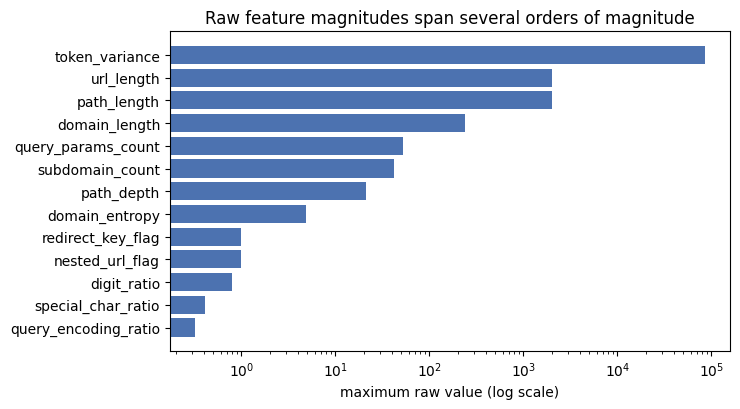

In [13]:
raw_summary = features_raw.agg(["min", "max", "mean", "std"]).T
raw_summary["range"] = raw_summary["max"] - raw_summary["min"]
display(raw_summary.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
max_values = features_raw.max().sort_values()
ax.barh(max_values.index, max_values.values, color="#4C72B0")
ax.set_xscale("log")
ax.set_xlabel("maximum raw value (log scale)")
ax.set_title("Raw feature magnitudes span several orders of magnitude")
plt.tight_layout()
plt.show()

## 2. Isolating the Features into Scaling Groups

Features are split into two lists according to the nature of the metric, and the binary flags are set aside:

| Group | Features | Scaler | Rationale |
|---|---|---|---|
| `min_max_cols` | Lengths and ratios: `url_length`, `domain_length`, `path_length`, `digit_ratio`, `special_char_ratio`, `query_encoding_ratio` | **MinMaxScaler** | Inherently bounded or absolute metrics. Min-Max maps them linearly into 0 to 1 without distorting their relative relationships. |
| `z_score_cols` | Counts, variance and entropy: `subdomain_count`, `path_depth`, `query_params_count`, `token_variance`, `domain_entropy` | **StandardScaler** | Distribution-based metrics that can be long-tailed. Standardization centres them at 0 with unit variance and preserves the shape of the distribution, instead of squeezing most values into a narrow band the way Min-Max does when a few values are extreme. |
| `binary_cols` | `redirect_key_flag`, `nested_url_flag` | none | Already 0 / 1, so scaling would add nothing. |

The three lists must **partition** the 13 features exactly: no feature missing, none scaled twice.

**Min-Max normalisation**

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Z-score standardisation**

$$z = \frac{x - \mu}{\sigma}$$


In [14]:
min_max_cols = ["url_length", "domain_length", "path_length",
                "digit_ratio", "special_char_ratio", "query_encoding_ratio"]
z_score_cols = ["subdomain_count", "path_depth", "query_params_count",
                "token_variance", "domain_entropy"]
binary_cols  = ["redirect_key_flag", "nested_url_flag"]

# the three groups must cover all 13 features exactly once
assert len(set(min_max_cols) | set(z_score_cols) | set(binary_cols)) == 13
assert len(min_max_cols) + len(z_score_cols) + len(binary_cols) == 13
assert set(min_max_cols + z_score_cols + binary_cols) == set(FEATURE_ORDER)

def scaling_of(col):
    return "MinMaxScaler" if col in min_max_cols else "StandardScaler" if col in z_score_cols else "none (binary)"

scaling_map = pd.DataFrame({
    "feature": FEATURE_ORDER,
    "level": [1 if c in LEVEL1 else 2 for c in FEATURE_ORDER],
    "scaling": [scaling_of(c) for c in FEATURE_ORDER],
}).set_index("feature")

print(f"MinMaxScaler: {len(min_max_cols)} features | StandardScaler: {len(z_score_cols)} features | "
      f"unscaled binary flags: {len(binary_cols)}")
scaling_map

MinMaxScaler: 6 features | StandardScaler: 5 features | unscaled binary flags: 2


,level,scaling
feature,,
url_length,1,MinMaxScaler
domain_length,1,MinMaxScaler
path_length,1,MinMaxScaler
subdomain_count,2,StandardScaler
path_depth,2,StandardScaler
query_params_count,2,StandardScaler
digit_ratio,2,MinMaxScaler
special_char_ratio,2,MinMaxScaler
token_variance,2,StandardScaler


## 3. Min-Max Normalisation (`MinMaxScaler`)

`MinMaxScaler` is fitted on `min_max_cols` and transforms every value linearly to the 0.0 to 1.0 boundary. For each feature it learns the observed minimum and maximum, so after transformation the smallest value becomes exactly 0 and the largest exactly 1. Relative distances between values are preserved.


In [15]:
scaled = features_raw.astype(float).copy()        # working copy; features_raw stays untouched

minmax_scaler = MinMaxScaler()
scaled[min_max_cols] = minmax_scaler.fit_transform(features_raw[min_max_cols])

minmax_params = pd.DataFrame({"x_min (learned)": minmax_scaler.data_min_,
                              "x_max (learned)": minmax_scaler.data_max_}, index=min_max_cols)
assert (minmax_params["x_max (learned)"] > minmax_params["x_min (learned)"]).all(), "constant column"
assert np.allclose(scaled[min_max_cols].min(), 0.0) and np.allclose(scaled[min_max_cols].max(), 1.0)

print("Fitted Min-Max parameters:")
display(minmax_params.round(4))
print("Scaled range check passed: every Min-Max feature now spans exactly [0, 1].")
scaled[min_max_cols].describe().round(4)

Fitted Min-Max parameters:


,x_min (learned),x_max (learned)
url_length,5.0000,2006.0000
domain_length,4.0000,236.0000
path_length,0.0000,1992.0000
digit_ratio,0.0000,0.8000
special_char_ratio,0.0109,0.4069
query_encoding_ratio,0.0000,0.3226


Scaled range check passed: every Min-Max feature now spans exactly [0, 1].


,url_length,domain_length,path_length,digit_ratio,special_char_ratio,query_encoding_ratio
count,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000
mean,0.0278,0.0681,0.0088,0.0896,0.3241,0.0123
std,0.0525,0.0844,0.0235,0.1359,0.1191,0.0642
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.0055,0.0302,0.0005,0.0000,0.2446,0.0000
50%,0.0120,0.0517,0.0035,0.0000,0.3190,0.0000
75%,0.0270,0.0776,0.0085,0.1347,0.3933,0.0000
max,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 4. Z-Score Standardisation (`StandardScaler`)

`StandardScaler` is fitted on `z_score_cols`. For each feature it learns the mean and standard deviation, then centres the distribution around zero with unit variance. Because it does not force a fixed range, a long tail stays a long tail, and the overall shape of the obfuscation signal in features such as `token_variance` and `domain_entropy` is preserved.


In [16]:
zscore_scaler = StandardScaler()
scaled[z_score_cols] = zscore_scaler.fit_transform(features_raw[z_score_cols])

zscore_params = pd.DataFrame({"mean mu (learned)": zscore_scaler.mean_,
                              "std sigma (learned)": zscore_scaler.scale_}, index=z_score_cols)
assert np.allclose(scaled[z_score_cols].mean(), 0.0, atol=1e-9)
assert np.allclose(np.std(scaled[z_score_cols].to_numpy(), axis=0), 1.0)

print("Fitted Z-score parameters:")
display(zscore_params.round(4))
print("Standardisation check passed: every Z-score feature has mean 0 and standard deviation 1.")
scaled[z_score_cols].describe().round(4)

Fitted Z-score parameters:


,mean mu (learned),std sigma (learned)
subdomain_count,1.0566,3.2403
path_depth,1.2170,1.4112
query_params_count,0.6369,1.9370
token_variance,121.5307,2027.4798
domain_entropy,3.2995,0.4809


Standardisation check passed: every Z-score feature has mean 0 and standard deviation 1.


,subdomain_count,path_depth,query_params_count,token_variance,domain_entropy
count,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000
mean,0.0000,-0.0000,-0.0000,0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001,1.0001
min,-0.3261,-0.8624,-0.3288,-0.0599,-3.3564
25%,-0.3261,-0.8624,-0.3288,-0.0577,-0.6778
50%,-0.0175,-0.1538,-0.3288,-0.0555,0.0493
75%,-0.0175,0.5548,-0.3288,-0.0453,0.6705
max,12.6357,14.0185,26.5172,41.5966,3.2124


## 5. Binary Flags Pass Through Unscaled

`redirect_key_flag` and `nested_url_flag` are already 0 / 1 indicators. They are carried into the matrix exactly as extracted.


In [17]:
scaled[binary_cols] = features_raw[binary_cols].astype(float)

assert scaled[binary_cols].equals(features_raw[binary_cols].astype(float)), "flags were modified"
assert set(np.unique(scaled[binary_cols].to_numpy())) <= {0.0, 1.0}
print("Flags untouched. Positive rate:", scaled[binary_cols].mean().round(4).to_dict())

Flags untouched. Positive rate: {'redirect_key_flag': 0.0079, 'nested_url_flag': 0.0233}


## 6. Array Generation

All 13 columns are now assembled, in the fixed `FEATURE_ORDER`, into a **strictly structured numerical array** that matches the input requirements of the classifiers: a two-dimensional `float64` matrix `X` of shape (rows, 13) with a matching target vector `y`. The `url` string is deliberately excluded, since the model input must be purely numeric. Row order is preserved from the input file, so any row can still be traced back to its URL by position.


In [18]:
X = scaled[FEATURE_ORDER].to_numpy(dtype=np.float64)
y = labels.to_numpy(dtype=np.int64)

assert X.ndim == 2 and X.shape == (len(raw), 13), X.shape
assert y.shape == (len(raw),)
assert np.isfinite(X).all(), "NaN or infinite value in the feature matrix"
assert list(scaled[FEATURE_ORDER].columns) == FEATURE_ORDER

print(f"Feature matrix X: shape {X.shape}, dtype {X.dtype}, {X.nbytes / 2**20:.2f} MB")
print(f"Target vector y : shape {y.shape}, dtype {y.dtype}, classes {np.unique(y).tolist()}")
print("\nFirst 5 rows of X:")
pd.DataFrame(X[:5], columns=FEATURE_ORDER).round(4)

Feature matrix X: shape (10000, 13), dtype float64, 0.99 MB
Target vector y : shape (10000,), dtype int64, classes [0, 1]

First 5 rows of X:


,url_length,domain_length,path_length,subdomain_count,path_depth,query_params_count,digit_ratio,special_char_ratio,token_variance,domain_entropy,redirect_key_flag,nested_url_flag,query_encoding_ratio
0,0.0260,0.0819,0.0065,-0.0175,0.5548,0.1875,0.3509,0.3712,-0.0445,1.2114,0.0,0.0,0.0000
1,0.0330,0.0474,0.0005,-0.0175,-0.8624,0.7037,0.3521,0.3992,-0.0555,0.9858,0.0,0.0,0.0000
2,0.0055,0.0517,0.0000,-0.0175,-0.8624,-0.3288,0.0000,0.2881,-0.0558,-0.7210,0.0,0.0,0.0000
3,0.0045,0.0431,0.0000,-0.3261,-0.8624,-0.3288,0.0000,0.1528,-0.0577,-0.5414,0.0,0.0,0.0000
4,0.0440,0.0388,0.0015,-0.0175,-0.1538,0.1875,0.1478,0.6784,-0.0590,-0.5667,1.0,0.0,0.3263


## 7. Raw vs. Scaled Comparison

The first row, side by side, shows the effect of the transformation: the large-magnitude length features collapse into the 0 to 1 range, the counts, variance and entropy are re-centred around zero, and the binary flags are unchanged. Afterwards, the before/after distributions show that scaling changes the **axis** but not the **shape** of each feature.


In [19]:
print("URL in row 0:", raw.loc[0, "url"][:100])
first_row = pd.DataFrame({
    "raw value": features_raw.iloc[0],
    "scaled value": scaled.iloc[0],
    "scaling": scaling_map["scaling"],
}).loc[FEATURE_ORDER]
first_row.round(4)

URL in row 0: 51-75-63-68.cprapid.com/eu/track.php?16d6oev751pp7e2ffowz


,raw value,scaled value,scaling
url_length,57.0000,0.0260,MinMaxScaler
domain_length,23.0000,0.0819,MinMaxScaler
path_length,13.0000,0.0065,MinMaxScaler
subdomain_count,1.0000,-0.0175,StandardScaler
path_depth,2.0000,0.5548,StandardScaler
query_params_count,1.0000,0.1875,StandardScaler
digit_ratio,0.2807,0.3509,MinMaxScaler
special_char_ratio,0.1579,0.3712,MinMaxScaler
token_variance,31.2889,-0.0445,StandardScaler
domain_entropy,3.8820,1.2114,StandardScaler


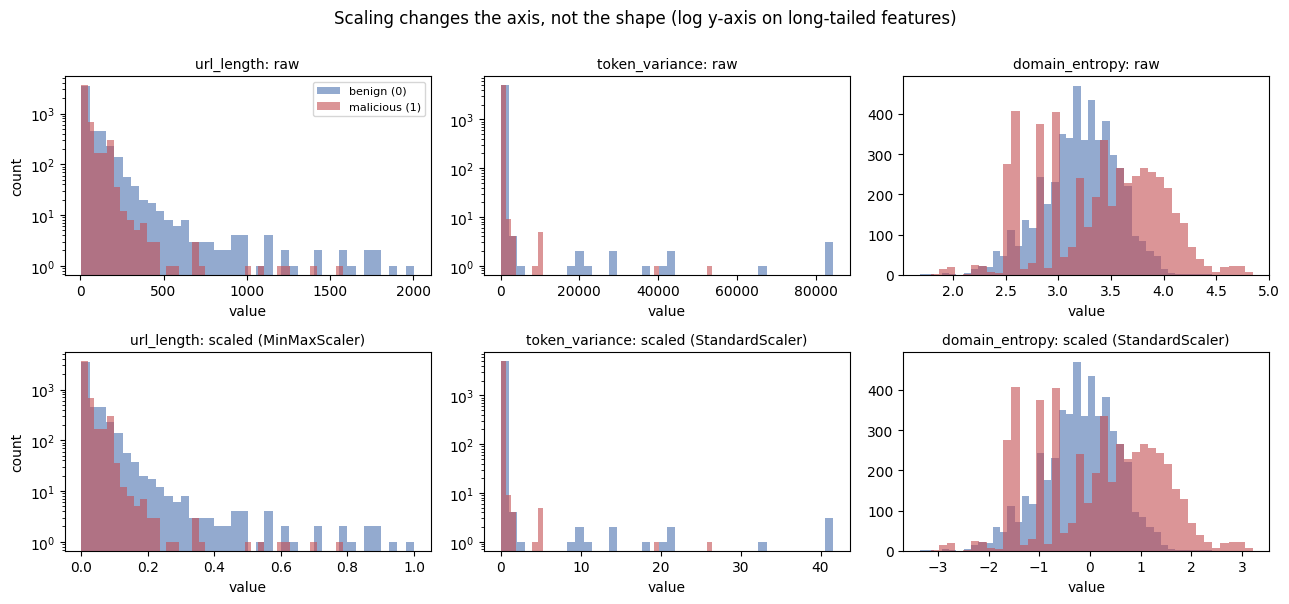

Share of the Min-Max range actually used by typical rows (scaled values):


,url_length,domain_length,path_length,digit_ratio,special_char_ratio,query_encoding_ratio
median,0.0120,0.0517,0.0035,0.0000,0.3190,0.0000
95th pct,0.0925,0.1552,0.0447,0.3947,0.5512,0.0743
99th pct,0.2114,0.5431,0.0617,0.5729,0.7035,0.2906
max,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [20]:
show = ["url_length", "token_variance", "domain_entropy"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, feat in enumerate(show):
    for i, (frame, row_name) in enumerate([(features_raw, "raw"), (scaled, f"scaled ({scaling_of(feat)})")]):
        ax = axes[i, j]
        ax.hist(frame.loc[labels == 0, feat], bins=40, alpha=0.6, color="#4C72B0", label="benign (0)")
        ax.hist(frame.loc[labels == 1, feat], bins=40, alpha=0.6, color="#C44E52", label="malicious (1)")
        if feat in ("url_length", "token_variance"):
            ax.set_yscale("log")                         # heavy right tails
        ax.set_title(f"{feat}: {row_name}", fontsize=10)
        ax.set_xlabel("value")
        if j == 0:
            ax.set_ylabel("count")
axes[0, 0].legend(fontsize=8)
plt.suptitle("Scaling changes the axis, not the shape (log y-axis on long-tailed features)", y=1.0)
plt.tight_layout()
plt.show()

print("Share of the Min-Max range actually used by typical rows (scaled values):")
display(scaled[min_max_cols].quantile([0.5, 0.95, 0.99, 1.0]).round(4).rename(index={0.5: "median", 0.95: "95th pct", 0.99: "99th pct", 1.0: "max"}))

**Reading the table above.** Min-Max scaling is sensitive to extreme values: a handful of unusually long URLs set the maximum, so the typical (median) URL lands close to 0 on the length features. The relative ordering and linear relationships are intact, and the features are now commensurate with the others, but this is worth remembering when interpreting scaled magnitudes.


## 8. Diagnostic: Does the Fitting Scope Matter?

The scalers above are fitted on **every row**, and the 80/20 train/test split happens afterwards, during model training. That means the held-out test rows have contributed to the learned minimum, maximum, mean and standard deviation, a mild form of information leakage from test data into preprocessing.

This optional diagnostic measures how much it matters. It splits the data 80/20 (stratified by class), fits the scalers on the **training rows only**, and compares the result with the all-rows scaling on the 20 % held-out rows. **Nothing here changes the exported matrix**; it only quantifies the effect, so you can state it (or decide to refit the scalers inside the training pipeline) with evidence.


In [21]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=RANDOM_SEED)

def scale_with_fit_rows(fit_rows):
    out = features_raw.astype(float).copy()
    mm = MinMaxScaler().fit(features_raw.iloc[fit_rows][min_max_cols])
    zs = StandardScaler().fit(features_raw.iloc[fit_rows][z_score_cols])
    out[min_max_cols] = mm.transform(features_raw[min_max_cols])
    out[z_score_cols] = zs.transform(features_raw[z_score_cols])
    return out

scaled_train_only = scale_with_fit_rows(train_idx)

diff = (scaled_train_only.iloc[test_idx] - scaled.iloc[test_idx]).abs()[min_max_cols + z_score_cols]
print(f"Held-out rows: {len(test_idx):,}  |  scalers fitted on {len(train_idx):,} training rows vs. all {len(y):,} rows\n")
print("Absolute difference in scaled values on the held-out rows:")
display(diff.agg(["mean", "max"]).T.round(5))

out_of_range = ((scaled_train_only.iloc[test_idx][min_max_cols] < 0) |
                (scaled_train_only.iloc[test_idx][min_max_cols] > 1)).sum()
print("Held-out values falling outside [0, 1] when Min-Max is fitted on training rows only:")
print(out_of_range.to_dict())

Held-out rows: 2,000  |  scalers fitted on 8,000 training rows vs. all 10,000 rows

Absolute difference in scaled values on the held-out rows:


,mean,max
url_length,0.00000,0.00000
domain_length,0.00000,0.00000
path_length,0.00000,0.00000
digit_ratio,0.01359,0.15556
special_char_ratio,0.00000,0.00000
query_encoding_ratio,0.00000,0.00000
subdomain_count,0.00550,0.24324
path_depth,0.00835,0.07345
query_params_count,0.00252,0.05740
token_variance,0.00460,0.14034


Held-out values falling outside [0, 1] when Min-Max is fitted on training rows only:
{'url_length': 0, 'domain_length': 0, 'path_length': 0, 'digit_ratio': 1, 'special_char_ratio': 0, 'query_encoding_ratio': 0}


## 9. Final Output: Scaled 13-Attribute Feature Matrix (CSV)

The scaled matrix is assembled (13 feature columns in `FEATURE_ORDER`, followed by the `label` target), validated one last time and exported as `Final Dataset_Scaled.csv`. This file is the direct input for the training and testing phases. The final cell displays the exported matrix.


In [22]:
df_scaled = scaled[FEATURE_ORDER].copy()
df_scaled["label"] = labels.values

# final validation
assert list(df_scaled.columns) == FEATURE_ORDER + ["label"]
assert df_scaled.shape == (len(raw), 14)                       # 13 features + label
assert df_scaled.notna().all().all() and np.isfinite(df_scaled.to_numpy()).all()
assert np.allclose(df_scaled[min_max_cols].min(), 0.0) and np.allclose(df_scaled[min_max_cols].max(), 1.0)
assert np.allclose(df_scaled[z_score_cols].mean(), 0.0, atol=1e-9)
assert df_scaled["label"].isin([0, 1]).all()

df_scaled.to_csv(OUTPUT_PATH, index=False)

print(f"Final scaled feature matrix: {df_scaled.shape[0]:,} rows x {df_scaled.shape[1]} columns "
      f"(13 scaled features + label)")
print(f"  MinMaxScaler on {len(min_max_cols)} features | StandardScaler on {len(z_score_cols)} features | "
      f"{len(binary_cols)} binary flags unscaled")
print("Saved to:", OUTPUT_PATH)
df_scaled

Final scaled feature matrix: 10,000 rows x 14 columns (13 scaled features + label)
  MinMaxScaler on 6 features | StandardScaler on 5 features | 2 binary flags unscaled
Saved to: ../Dataset/Final_Dataset.csv


,url_length,domain_length,path_length,subdomain_count,path_depth,query_params_count,digit_ratio,special_char_ratio,token_variance,domain_entropy,redirect_key_flag,nested_url_flag,query_encoding_ratio,label
0,0.025987,0.081897,0.006526,-0.017467,0.554843,0.187458,0.350877,0.371156,-0.044509,1.211362,0.0,0.0,0.000000,1
1,0.032984,0.047414,0.000502,-0.017467,-0.862381,0.703727,0.352113,0.399238,-0.055506,0.985763,0.0,0.0,0.000000,0
2,0.005497,0.051724,0.000000,-0.017467,-0.862381,-0.328812,0.000000,0.288082,-0.055832,-0.720954,0.0,0.0,0.000000,0
3,0.004498,0.043103,0.000000,-0.326080,-0.862381,-0.328812,0.000000,0.152789,-0.057722,-0.541433,0.0,0.0,0.000000,0
4,0.043978,0.038793,0.001506,-0.017467,-0.153769,0.187458,0.147849,0.678442,-0.058988,-0.566724,1.0,0.0,0.326316,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.096452,0.780172,0.006526,9.240911,0.554843,-0.328812,0.050505,0.418819,-0.058688,0.202427,0.0,0.0,0.000000,1
9996,0.004498,0.012931,0.003514,-0.326080,-0.153769,-0.328812,0.178571,0.333179,-0.057969,-1.023446,0.0,0.0,0.000000,1
9997,0.088456,0.047414,0.054217,-0.017467,2.680680,1.736267,0.151099,0.277675,-0.011853,-0.677830,0.0,0.0,0.000000,1
9998,0.010995,0.073276,0.003012,-0.017467,-0.153769,-0.328812,0.000000,0.440077,-0.054862,0.661887,0.0,0.0,0.000000,0
